Output()

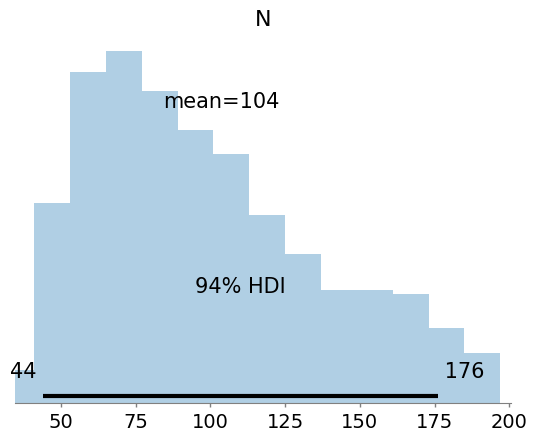

Mean: 103.73725
Median: 97.0
HDI: [ 45 181]
Estimare clasica: 75.0
P(N > 100): 0.465


Output()

Output()

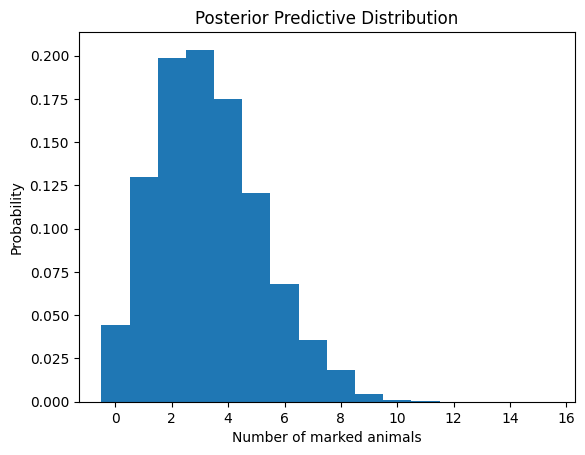

In [4]:
#Exercise 1

import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

M = 20
n = 15
Y = 4
#a
with pm.Model() as model:

  N = pm.DiscreteUniform("N", lower = 20, upper = 200)

  obs = pm.HyperGeometric("obs", N = N, k = M, n = n, observed = Y)

  idata = pm.sample(draws = 2000, tune = 1000, chains = 4, random_seed = 42)

  az.plot_posterior(idata, var_names=["N"])

  plt.show()

#b

# Posterior mean E[N|Y=4]

posterior = idata.posterior["N"].values.flatten()
media = np.mean(posterior)
print("Mean:", media)

# Posterior median

mediana = np.median(posterior)
print("Median:",mediana)

# 95% HDI interval


hdi = az.hdi(posterior, hdi_prob=0.95)
print("HDI:", hdi)

# N^=(M*n)/Y => N^=(20*15)/4 => N^=75 => 75 animals in clasic estimation

estimare_clasica = (M * n) / Y

print("Estimare clasica:", estimare_clasica)

#c P(N>10|y=4)

probabilitate = np.mean(posterior > 100)

print("P(N > 100):", probabilitate)

#d

with pm.Model() as model:
    N = pm.DiscreteUniform("N", lower=20, upper=200)

    obs = pm.HyperGeometric("obs", N=N, k=M, n=n, observed=Y)

    y_new = pm.HyperGeometric("y_new", N=N, k=M, n=15)

    idata = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42)

    predictive = pm.sample_posterior_predictive(idata, var_names=["y_new"], random_seed=42)

    y_new_samples = predictive.posterior_predictive["y_new"].values.flatten()

plt.hist(y_new_samples, bins=np.arange(-0.5, 16.5, 1), density=True)
plt.xlabel("Number of marked animals")
plt.ylabel("Probability")
plt.title("Posterior Predictive Distribution")
plt.show()

plt.show()

Output()

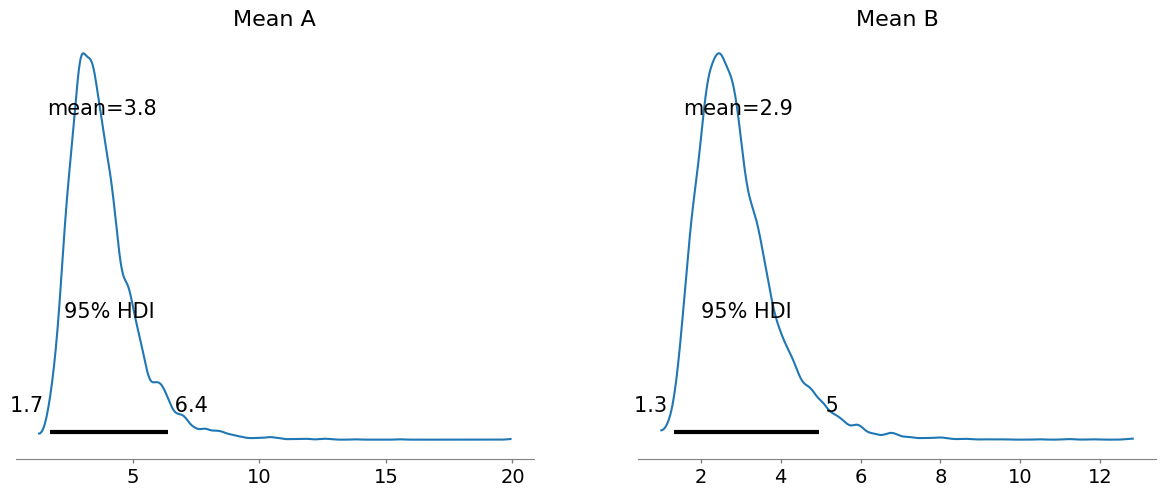

P(B is faster than A): 0.711


Output()

P(new B patient recovers faster): 0.50075


In [7]:
#Exercise 2

import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

A = [3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9]
B = [2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7]
#a

with pm.Model() as model:

    lambda_A = pm.Gamma("lambda_A", alpha=2, beta=4)
    lambda_B = pm.Gamma("lambda_B", alpha=2, beta=4)

    obs_A = pm.Exponential("obs_A", lam=lambda_A, observed=A)

    obs_B = pm.Exponential("obs_B", lam=lambda_B, observed=B)

    idata = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42)

#b

lambda_A_samples = idata.posterior["lambda_A"].values.flatten()
lambda_B_samples = idata.posterior["lambda_B"].values.flatten()

mean_A = 1 / lambda_A_samples
mean_B = 1 / lambda_B_samples

az.plot_posterior({"Mean A": mean_A, "Mean B": mean_B}, hdi_prob=0.95)

plt.show()

#c P(E[XB]<E[XA]|date)

prob = np.mean(mean_B < mean_A)

print("P(B is faster than A):", prob)


#d

with pm.Model() as predictive_model:

    lambda_A = pm.Gamma("lambda_A", alpha=2, beta=4)
    lambda_B = pm.Gamma("lambda_B", alpha=2, beta=4)

    x_A = pm.Exponential("x_A", lam=lambda_A)
    x_B = pm.Exponential("x_B", lam=lambda_B)

    predictive_idata = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42)

x_A_samples = predictive_idata.posterior["x_A"].values.flatten()
x_B_samples = predictive_idata.posterior["x_B"].values.flatten()

prob_new = np.mean(x_B_samples < x_A_samples)

print("P(new B patient recovers faster):", prob_new)

Output()

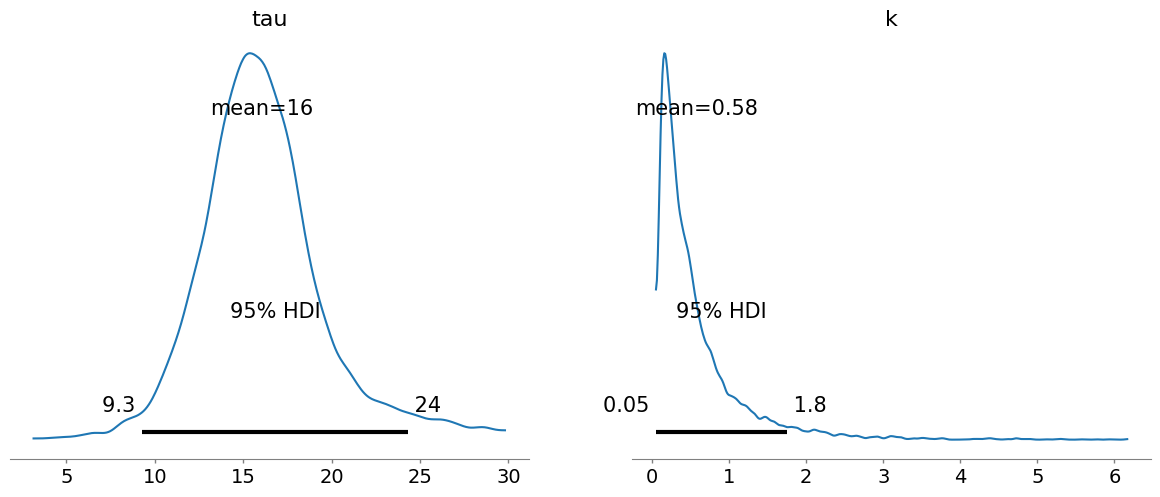

P(lambda2 > lambda1): 1.0


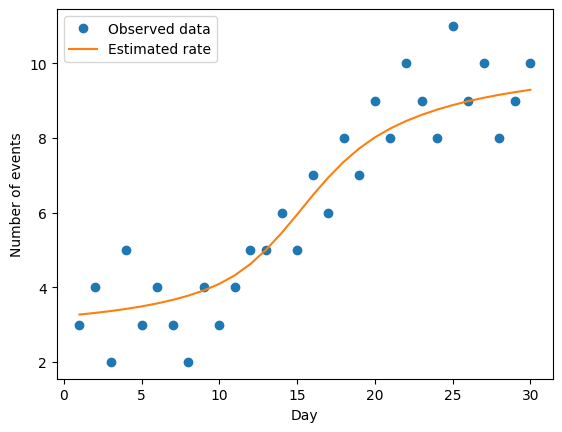

Output()

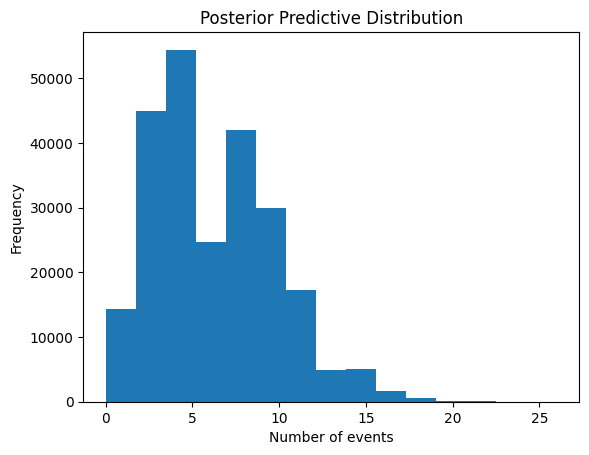

In [11]:
#Exercise 3

import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

Y = np.array([
    3, 4, 2, 5, 3, 4, 3, 2, 4, 3,
    4, 5, 5, 6, 5, 7, 6, 8, 7, 9,
    8, 10, 9, 8, 11, 9, 10, 8, 9, 10
])

t = np.arange(1, 31)

#a

with pm.Model() as model:

    lambda1 = pm.Exponential("lambda1", lam=0.2)
    lambda2 = pm.Exponential("lambda2", lam=0.2)

    tau = pm.Uniform("tau", lower=1, upper=30)

    k = pm.Exponential("k", lam=1)

    lambda_t = lambda1 + ((lambda2 - lambda1) / (1 + pm.math.exp(-k * (t - tau))))

    lambda_t = pm.Deterministic("lambda_t", lambda_t)

    obs = pm.Poisson("obs", mu=lambda_t, observed=Y)

    idata = pm.sample(draws=2000, tune=2000, chains=4, target_accept=0.95, random_seed=42)
#b

az.plot_posterior(idata, var_names=["tau", "k"], hdi_prob=0.95)

plt.show()

#c P(lambda2>lambda1|date)

lambda1_samples = idata.posterior["lambda1"].values.flatten()
lambda2_samples = idata.posterior["lambda2"].values.flatten()

prob = np.mean(lambda2_samples > lambda1_samples)

print("P(lambda2 > lambda1):", prob)

lambda_t_samples = idata.posterior["lambda_t"].values

lambda_t_mean = lambda_t_samples.mean(axis=(0, 1))

plt.plot(t, Y, "o", label="Observed data")
plt.plot(t, lambda_t_mean, label="Estimated rate")

plt.xlabel("Day")
plt.ylabel("Number of events")
plt.legend()
plt.show()

#c

# d - Posterior predictive

with model:
    ppc = pm.sample_posterior_predictive(idata, random_seed=42)

y_pred = ppc.posterior_predictive["obs"].values.flatten()

plt.hist(y_pred, bins=15)

plt.xlabel("Number of events")
plt.ylabel("Frequency")
plt.title("Posterior Predictive Distribution")

plt.show()